In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

DATA_PATH = Path("../data/processed/all_transactions.csv")

transactions = pd.read_csv(DATA_PATH)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

transactions = transactions.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Dataset shape:", transactions.shape)
display(transactions.head())


Dataset shape: (99975, 12)


,transaction_id,timestamp,sender_id,receiver_id,transaction_type,amount,sender_balance_before,sender_balance_after,device_id,location,is_fraud,fraud_scenario
0,TXN_0000001,2026-01-01 00:00:34.132897690,ACC_005643,ACC_003307,CASH_OUT,226.47,41772.42,41545.95,DEV_005643,Gaziantep,0,NORMAL
1,TXN_0000002,2026-01-01 00:00:34.427735075,ACC_002326,ACC_002724,PAYMENT,381.23,88299.25,87918.02,DEV_002326,Antalya,0,NORMAL
2,TXN_0000003,2026-01-01 00:00:49.868826972,ACC_002387,ACC_005028,TRANSFER,36.73,213644.33,213607.60,DEV_002387,Bursa,0,NORMAL
3,TXN_0000004,2026-01-01 00:01:11.188848846,ACC_002952,ACC_009419,CASH_OUT,20.02,4911.69,4891.67,DEV_002952,Konya,0,NORMAL
4,TXN_0000005,2026-01-01 00:02:02.367877342,ACC_004445,ACC_007201,TRANSFER,49.03,8264.50,8215.47,DEV_004445,Istanbul,0,NORMAL


In [2]:

# İşlem tutarının logaritmik dönüşümü
transactions["amount_log"] = np.log1p(
    transactions["amount"]
)

# İşlem saati
transactions["hour"] = (
    transactions["timestamp"].dt.hour
)

# Haftanın günü (0 = Monday, 6 = Sunday)
transactions["day_of_week"] = (
    transactions["timestamp"].dt.dayofweek
)

# Gün sonu / hafta sonu bilgisi
transactions["is_weekend"] = (
    transactions["day_of_week"] >= 5
).astype(int)

# İşlem türünün kategorik kodu
transactions["transaction_type_code"] = (
    transactions["transaction_type"].astype("category").cat.codes
)

# Gönderen ve alıcı aynı mı?
transactions["is_self_transfer"] = (
    transactions["sender_id"] == transactions["receiver_id"]
).astype(int)

display(
    transactions[
        [
            "amount",
            "amount_log",
            "hour",
            "day_of_week",
            "is_weekend",
            "transaction_type_code",
            "is_self_transfer"
        ]
    ].head(10)
)


,amount,amount_log,hour,day_of_week,is_weekend,transaction_type_code,is_self_transfer
0,226.47,5.427018,0,3,0,1,0
1,381.23,5.946023,0,3,0,2,0
2,36.73,3.630456,0,3,0,3,0
3,20.02,3.045474,0,3,0,1,0
4,49.03,3.912623,0,3,0,3,0
5,46.13,3.852910,0,3,0,3,0
6,78.15,4.371345,0,3,0,2,0
7,29.88,3.430109,0,3,0,0,0
8,58.54,4.086648,0,3,0,3,0
9,162.97,5.099683,0,3,0,1,0


In [3]:

new_features = [
    "amount_log",
    "hour",
    "day_of_week",
    "is_weekend",
    "transaction_type_code",
    "is_self_transfer"
]

print("New feature count:", len(new_features))

display(
    transactions[new_features].describe().round(2)
)

print("\nMissing values:")
print(transactions[new_features].isnull().sum())


New feature count: 6


,amount_log,hour,day_of_week,is_weekend,transaction_type_code,is_self_transfer
count,99975.00,99975.00,99975.00,99975.00,99975.00,99975.0
mean,3.93,11.51,3.03,0.27,1.82,0.0
std,1.16,6.92,1.94,0.44,1.03,0.0
min,0.22,0.00,0.00,0.00,0.00,0.0
25%,3.11,6.00,1.00,0.00,1.00,0.0
50%,3.85,12.00,3.00,0.00,2.00,0.0
75%,4.65,18.00,5.00,1.00,3.00,0.0
max,9.21,23.00,6.00,1.00,3.00,0.0



Missing values:
amount_log               0
hour                     0
day_of_week              0
is_weekend               0
transaction_type_code    0
is_self_transfer         0
dtype: int64


In [4]:

# İşlemleri gönderen hesap ve zamana göre sırala
transactions = transactions.sort_values(
    ["sender_id", "timestamp"]
).copy()

# Yeni özellikler için boş alanlar oluştur
transactions["tx_count_1h"] = 0
transactions["tx_count_24h"] = 0
transactions["amount_sum_1h"] = 0.0
transactions["amount_sum_24h"] = 0.0

# Her hesabın geçmiş işlemlerini ayrı hesapla
for sender_id, group in transactions.groupby("sender_id"):

    group = group.sort_values("timestamp")

    time_data = group.set_index("timestamp")

    # Mevcut işlem hariç, önceki 1 saat
    count_1h = (
        time_data["transaction_id"]
        .rolling("1h", closed="left")
        .count()
    )

    # Mevcut işlem hariç, önceki 24 saat
    count_24h = (
        time_data["transaction_id"]
        .rolling("24h", closed="left")
        .count()
    )

    amount_1h = (
        time_data["amount"]
        .rolling("1h", closed="left")
        .sum()
    )

    amount_24h = (
        time_data["amount"]
        .rolling("24h", closed="left")
        .sum()
    )

    # Hesaplanan değerleri orijinal satır indekslerine yerleştir
    transactions.loc[group.index, "tx_count_1h"] = (
        count_1h.to_numpy()
    )

    transactions.loc[group.index, "tx_count_24h"] = (
        count_24h.to_numpy()
    )

    transactions.loc[group.index, "amount_sum_1h"] = (
        amount_1h.to_numpy()
    )

    transactions.loc[group.index, "amount_sum_24h"] = (
        amount_24h.to_numpy()
    )

display(
    transactions[
        [
            "sender_id",
            "timestamp",
            "amount",
            "tx_count_1h",
            "tx_count_24h",
            "amount_sum_1h",
            "amount_sum_24h"
        ]
    ].head(15)
)


,sender_id,timestamp,amount,tx_count_1h,tx_count_24h,amount_sum_1h,amount_sum_24h
12773,ACC_000001,2026-01-04 20:22:16.126060823,86.30,NaN,NaN,NaN,NaN
43973,ACC_000001,2026-01-14 06:18:30.107749047,81.95,NaN,NaN,NaN,NaN
70596,ACC_000001,2026-01-22 04:35:57.384471431,23.80,NaN,NaN,NaN,NaN
71659,ACC_000001,2026-01-22 12:11:39.969563692,684.36,NaN,1.0,NaN,23.80
74193,ACC_000001,2026-01-23 06:14:32.468053156,14.54,NaN,1.0,NaN,684.36
78430,ACC_000001,2026-01-24 12:30:05.346765148,772.78,NaN,NaN,NaN,NaN
79675,ACC_000001,2026-01-24 21:16:20.902574836,68.76,NaN,1.0,NaN,772.78
83671,ACC_000001,2026-01-26 02:09:27.984307222,118.67,NaN,NaN,NaN,NaN
84330,ACC_000001,2026-01-26 06:50:29.294099261,242.45,NaN,1.0,NaN,118.67
87214,ACC_000001,2026-01-27 03:52:29.156524083,124.66,NaN,1.0,NaN,242.45


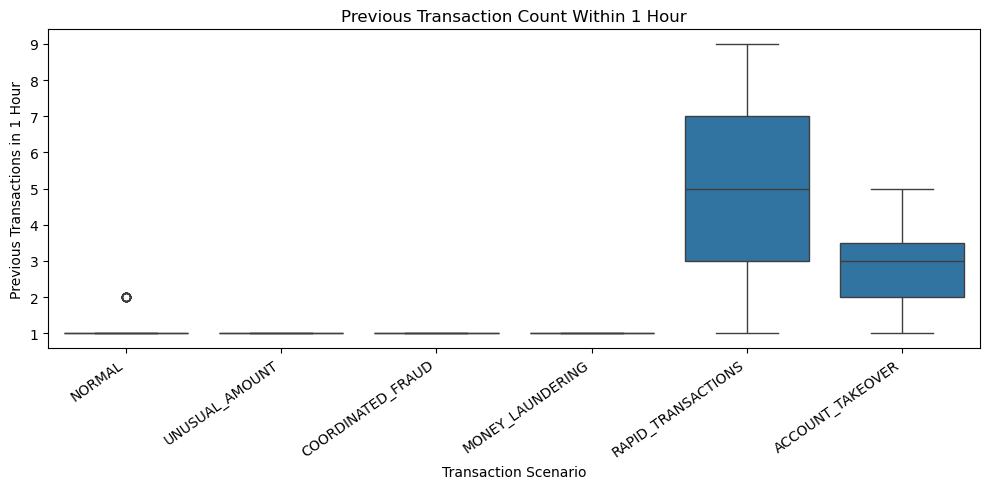

In [5]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=transactions,
    x="fraud_scenario",
    y="tx_count_1h"
)

plt.title("Previous Transaction Count Within 1 Hour")
plt.xlabel("Transaction Scenario")
plt.ylabel("Previous Transactions in 1 Hour")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [6]:

behavior_comparison = (
    transactions.groupby("is_fraud")
    [
        [
            "tx_count_1h",
            "tx_count_24h",
            "amount_sum_1h",
            "amount_sum_24h"
        ]
    ]
    .mean()
    .round(2)
)

display(behavior_comparison)


,tx_count_1h,tx_count_24h,amount_sum_1h,amount_sum_24h
is_fraud,,,,
0,1.01,1.18,114.93,137.66
1,3.76,3.08,2144.72,1489.44


In [7]:

behavior_features = [
    "tx_count_1h",
    "tx_count_24h",
    "amount_sum_1h",
    "amount_sum_24h"
]

print("Missing values:")
print(transactions[behavior_features].isnull().sum())

print("\nFeature statistics:")
display(transactions[behavior_features].describe().round(2))


Missing values:
tx_count_1h       98145
tx_count_24h      71844
amount_sum_1h     98145
amount_sum_24h    71844
dtype: int64

Feature statistics:


,tx_count_1h,tx_count_24h,amount_sum_1h,amount_sum_24h
count,1830.00,28131.00,1830.00,28131.00
mean,1.79,1.23,692.81,176.05
std,1.78,0.70,1258.37,592.51
min,1.00,1.00,1.17,0.55
25%,1.00,1.00,29.11,24.80
50%,1.00,1.00,82.16,54.98
75%,1.00,1.00,679.78,127.18
max,9.00,12.00,10000.00,10780.92


In [8]:

# Önce hesap ve zaman sıralamasını garanti edelim.
transactions = transactions.sort_values(
    ["sender_id", "timestamp"]
).copy()

# Mevcut işlem hariç geçmiş işlem ortalaması
transactions["previous_avg_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(
        lambda x: x.shift(1).expanding().mean()
    )
)

# Mevcut işlem hariç geçmiş işlem standart sapması
transactions["previous_std_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(
        lambda x: x.shift(1).expanding().std()
    )
)

# Hesabın geçmiş işlem kaydı var mı?
transactions["has_transaction_history"] = (
    transactions["previous_avg_amount"].notna()
).astype(int)

display(
    transactions[
        [
            "sender_id",
            "timestamp",
            "amount",
            "previous_avg_amount",
            "previous_std_amount",
            "has_transaction_history"
        ]
    ].head(20)
)


,sender_id,timestamp,amount,previous_avg_amount,previous_std_amount,has_transaction_history
12773,ACC_000001,2026-01-04 20:22:16.126060823,86.30,NaN,NaN,0
43973,ACC_000001,2026-01-14 06:18:30.107749047,81.95,86.300000,NaN,1
70596,ACC_000001,2026-01-22 04:35:57.384471431,23.80,84.125000,3.075914,1
71659,ACC_000001,2026-01-22 12:11:39.969563692,684.36,64.016667,34.896502,1
74193,ACC_000001,2026-01-23 06:14:32.468053156,14.54,219.102500,311.477618,1
78430,ACC_000001,2026-01-24 12:30:05.346765148,772.78,178.190000,284.838363,1
79675,ACC_000001,2026-01-24 21:16:20.902574836,68.76,277.288333,351.893724,1
83671,ACC_000001,2026-01-26 02:09:27.984307222,118.67,247.498571,330.761248,1
84330,ACC_000001,2026-01-26 06:50:29.294099261,242.45,231.395000,309.594255,1
87214,ACC_000001,2026-01-27 03:52:29.156524083,124.66,232.623333,289.622352,1


In [9]:

# Mevcut işlem / geçmiş ortalama
transactions["amount_vs_avg"] = (
    transactions["amount"] /
    transactions["previous_avg_amount"].replace(0, np.nan)
)

# Z-score hesaplama
transactions["amount_zscore"] = (
    transactions["amount"] - transactions["previous_avg_amount"]
) / transactions["previous_std_amount"].replace(0, np.nan)

# İlk işlemde geçmiş veri olmadığı için NaN oluşabilir.
# Bu işlemleri sıfır ile dolduruyoruz.
transactions[
    ["amount_vs_avg", "amount_zscore"]
] = transactions[
    ["amount_vs_avg", "amount_zscore"]
].replace([np.inf, -np.inf], np.nan).fillna(0)

display(
    transactions[
        [
            "amount",
            "previous_avg_amount",
            "amount_vs_avg",
            "amount_zscore"
        ]
    ].head(20)
)


,amount,previous_avg_amount,amount_vs_avg,amount_zscore
12773,86.30,NaN,0.000000,0.000000
43973,81.95,86.300000,0.949594,0.000000
70596,23.80,84.125000,0.282912,-19.612054
71659,684.36,64.016667,10.690341,17.776662
74193,14.54,219.102500,0.066362,-0.656749
78430,772.78,178.190000,4.336831,2.087465
79675,68.76,277.288333,0.247973,-0.592589
83671,118.67,247.498571,0.479478,-0.389491
84330,242.45,231.395000,1.047775,0.035708
87214,124.66,232.623333,0.535888,-0.372773


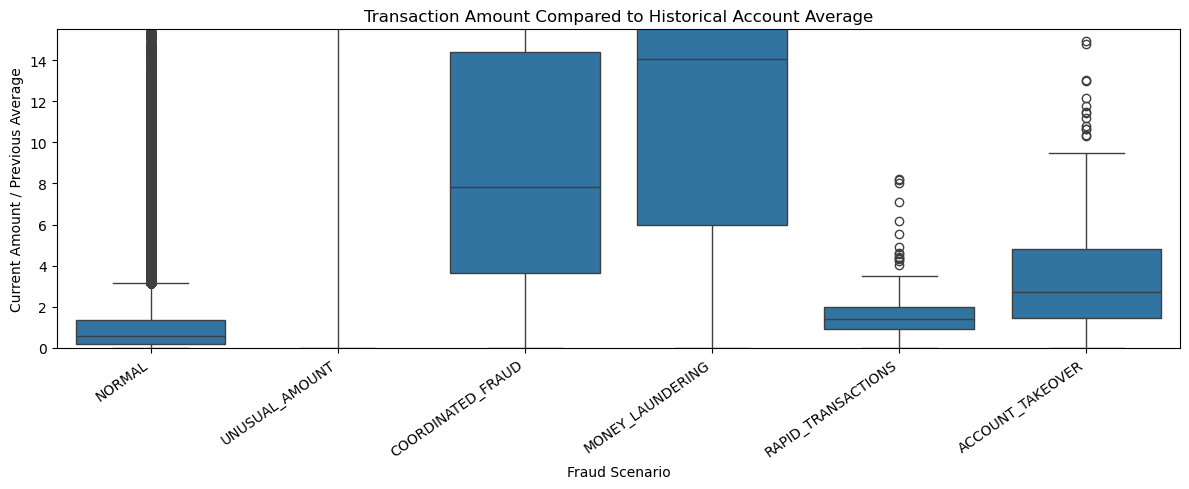

In [10]:

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=transactions,
    x="fraud_scenario",
    y="amount_vs_avg"
)

plt.title("Transaction Amount Compared to Historical Account Average")
plt.xlabel("Fraud Scenario")
plt.ylabel("Current Amount / Previous Average")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, transactions["amount_vs_avg"].quantile(0.99))
plt.tight_layout()
plt.show()


In [11]:

deviation_features = [
    "previous_avg_amount",
    "previous_std_amount",
    "has_transaction_history",
    "amount_vs_avg",
    "amount_zscore"
]

print("Missing values:")
print(transactions[deviation_features].isnull().sum())

print("\nFeature statistics:")
display(transactions[deviation_features].describe().round(2))


Missing values:
previous_avg_amount        10000
previous_std_amount        19996
has_transaction_history        0
amount_vs_avg                  0
amount_zscore                  0
dtype: int64

Feature statistics:


,previous_avg_amount,previous_std_amount,has_transaction_history,amount_vs_avg,amount_zscore
count,89975.00,79979.00,99975.0,99975.00,99975.00
mean,120.43,142.76,0.9,1.69,16.16
std,262.05,418.59,0.3,9.67,4441.82
min,1.10,0.00,0.0,0.00,-1203.92
25%,38.55,28.05,1.0,0.21,-0.63
50%,61.77,53.90,1.0,0.59,-0.02
75%,120.80,115.74,1.0,1.42,0.24
max,10000.00,7065.39,1.0,1245.33,1403655.75


In [12]:

unusual_check = transactions[
    transactions["fraud_scenario"] == "UNUSUAL_AMOUNT"
][[
    "sender_id",
    "timestamp",
    "amount",
    "previous_avg_amount",
    "previous_std_amount",
    "amount_vs_avg",
    "amount_zscore",
    "has_transaction_history"
]]

display(unusual_check.head(15))


,sender_id,timestamp,amount,previous_avg_amount,previous_std_amount,amount_vs_avg,amount_zscore,has_transaction_history
87898,ACC_000011,2026-01-27 08:44:51,788.45,39.043750,39.294408,20.194013,19.071575,1
42553,ACC_000020,2026-01-13 20:15:24,10000.00,44.645000,39.836547,223.989249,249.905070,1
52512,ACC_000021,2026-01-16 19:26:10,10000.00,204.641429,252.639274,48.865961,38.772113,1
94240,ACC_000043,2026-01-29 06:51:53,6626.93,64.661000,46.987783,102.487280,139.659046,1
80107,ACC_000108,2026-01-25 00:14:12,1732.88,17.710000,7.623569,97.847544,224.982559,1
1049,ACC_000132,2026-01-01 07:10:23,10000.00,NaN,NaN,0.000000,0.000000,0
72973,ACC_000245,2026-01-22 21:27:46,10000.00,98.831429,109.764201,101.182388,90.203987,1
6397,ACC_000282,2026-01-02 21:59:44,4436.49,NaN,NaN,0.000000,0.000000,0
66970,ACC_000288,2026-01-21 02:26:55,2142.60,39.670000,38.992012,54.010587,53.932328,1
46008,ACC_000290,2026-01-14 21:06:47,2187.26,12.103333,9.171534,180.715505,237.163892,1


In [13]:

scenario_check = (
    transactions.groupby("fraud_scenario")
    .agg(
        count=("amount_vs_avg", "count"),
        median_ratio=("amount_vs_avg", "median"),
        mean_ratio=("amount_vs_avg", "mean"),
        zero_ratio=("amount_vs_avg", lambda x: (x == 0).mean()),
        median_amount=("amount", "median"),
        median_history=("has_transaction_history", "median")
    )
    .round(3)
)

display(scenario_check)


,count,median_ratio,mean_ratio,zero_ratio,median_amount,median_history
fraud_scenario,,,,,,
ACCOUNT_TAKEOVER,299,2.707,5.679,0.020,1194.440,1.0
COORDINATED_FRAUD,300,7.813,11.789,0.063,630.065,1.0
MONEY_LAUNDERING,300,14.046,18.347,0.043,1005.155,1.0
NORMAL,98476,0.580,1.295,0.101,45.150,1.0
RAPID_TRANSACTIONS,300,1.395,1.712,0.020,290.335,1.0
UNUSUAL_AMOUNT,300,70.421,101.026,0.130,7379.870,1.0


In [14]:

import networkx as nx

# Yönlü bir finansal işlem grafiği oluşturuyoruz.
G = nx.DiGraph()

# İşlemleri graph'a ekliyoruz.
for row in transactions.itertuples(index=False):

    G.add_edge(
        row.sender_id,
        row.receiver_id,
        amount=row.amount,
        timestamp=row.timestamp,
        is_fraud=row.is_fraud
    )

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

print("Is directed:", G.is_directed())


Number of nodes: 10000
Number of edges: 99925
Is directed: True


In [15]:

print("Graph Statistics")

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("Average in-degree:",
      np.mean([degree for _, degree in G.in_degree()]))

print("Average out-degree:",
      np.mean([degree for _, degree in G.out_degree()]))

print("Number of connected components:",
      nx.number_weakly_connected_components(G))


Graph Statistics
Nodes: 10000
Edges: 99925
Average in-degree: 9.9925
Average out-degree: 9.9925
Number of connected components: 1


In [16]:

graph_features = pd.DataFrame({
    "account_id": list(G.nodes()),
    "in_degree": [
        G.in_degree(node) for node in G.nodes()
    ],
    "out_degree": [
        G.out_degree(node) for node in G.nodes()
    ],
    "in_strength": [
        G.in_degree(node, weight="amount") for node in G.nodes()
    ],
    "out_strength": [
        G.out_degree(node, weight="amount") for node in G.nodes()
    ]
})

graph_features["total_connections"] = (
    graph_features["in_degree"]
    + graph_features["out_degree"]
)

display(graph_features.head(10))

print("Graph feature shape:", graph_features.shape)


,account_id,in_degree,out_degree,in_strength,out_strength,total_connections
0,ACC_000001,10,12,542.59,2365.02,22
1,ACC_000850,9,6,373.87,1732.03,15
2,ACC_009855,12,6,943.90,365.53,18
3,ACC_007577,10,11,2075.33,2436.18,21
4,ACC_005961,15,11,1573.38,491.80,26
5,ACC_007599,18,14,1566.00,738.89,32
6,ACC_005827,6,10,970.46,10902.01,16
7,ACC_008690,12,9,975.42,795.76,21
8,ACC_008042,12,8,1545.26,380.61,20
9,ACC_007521,15,9,1267.85,422.55,24


Graph feature shape: (10000, 6)


In [17]:

sender_graph_features = graph_features.add_prefix("sender_")
sender_graph_features = sender_graph_features.rename(
    columns={"sender_account_id": "sender_id"}
)

receiver_graph_features = graph_features.add_prefix("receiver_")
receiver_graph_features = receiver_graph_features.rename(
    columns={"receiver_account_id": "receiver_id"}
)

transactions = transactions.merge(
    sender_graph_features,
    on="sender_id",
    how="left"
)

transactions = transactions.merge(
    receiver_graph_features,
    on="receiver_id",
    how="left"
)

print("Updated dataset shape:", transactions.shape)

display(
    transactions[
        [
            "sender_id",
            "receiver_id",
            "sender_out_degree",
            "sender_in_degree",
            "receiver_in_degree",
            "receiver_out_degree"
        ]
    ].head()
)


Updated dataset shape: (99975, 37)


,sender_id,receiver_id,sender_out_degree,sender_in_degree,receiver_in_degree,receiver_out_degree
0,ACC_000001,ACC_000850,12,10,9,6
1,ACC_000001,ACC_009855,12,10,12,6
2,ACC_000001,ACC_007577,12,10,10,11
3,ACC_000001,ACC_005961,12,10,15,11
4,ACC_000001,ACC_007599,12,10,18,14


In [19]:

import time

start_time = time.time()

# Hesapların bağlantı sayılarını doğrudan çıkar
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

n_nodes = G.number_of_nodes()

centrality_features = pd.DataFrame({
    "account_id": list(G.nodes()),
    "in_degree": [in_degree[n] for n in G.nodes()],
    "out_degree": [out_degree[n] for n in G.nodes()]
})

# NetworkX Degree Centrality formülü
centrality_features["degree_centrality"] = (
    centrality_features["in_degree"]
    + centrality_features["out_degree"]
) / (2 * (n_nodes - 1))

print("Execution time:", round(time.time() - start_time, 2), "seconds")

display(
    centrality_features.sort_values(
        "degree_centrality",
        ascending=False
    ).head(10)
)


Execution time: 0.14 seconds


,account_id,in_degree,out_degree,degree_centrality
3304,ACC_005575,27,17,0.00220
4688,ACC_009527,23,18,0.00205
6428,ACC_008824,24,16,0.00200
2323,ACC_006895,18,21,0.00195
3977,ACC_004303,18,21,0.00195
6816,ACC_004111,19,19,0.00190
4272,ACC_003930,18,20,0.00190
3940,ACC_009216,17,21,0.00190
2262,ACC_006801,27,10,0.00185
74,ACC_005406,20,17,0.00185


In [20]:

start_time = time.time()

pagerank_scores = nx.pagerank(
    G,
    weight="amount",
    max_iter=100,
    tol=1e-6
)

centrality_features["pagerank"] = (
    centrality_features["account_id"]
    .map(pagerank_scores)
)

print(
    "Execution time:",
    round(time.time() - start_time, 2),
    "seconds"
)

display(
    centrality_features.nlargest(
        10, "pagerank"
    )
)


Execution time: 0.21 seconds


,account_id,in_degree,out_degree,degree_centrality,pagerank
2262,ACC_006801,27,10,0.00185,0.000626
3304,ACC_005575,27,17,0.00220,0.000550
7089,ACC_004209,24,8,0.00160,0.000545
392,ACC_000474,25,8,0.00165,0.000532
1580,ACC_009971,17,8,0.00125,0.000529
2747,ACC_009391,20,10,0.00150,0.000503
2304,ACC_004685,22,8,0.00150,0.000500
2685,ACC_005594,22,8,0.00150,0.000497
8203,ACC_003953,20,7,0.00135,0.000493
8771,ACC_003681,19,10,0.00145,0.000488


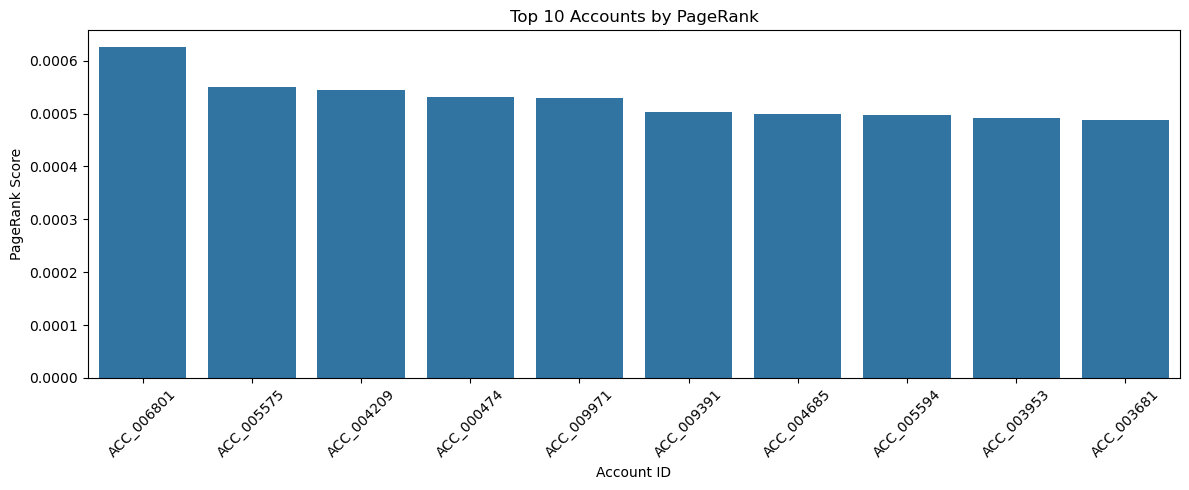

In [21]:

top_accounts = centrality_features.nlargest(
    10, "pagerank"
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=top_accounts,
    x="account_id",
    y="pagerank"
)

plt.title("Top 10 Accounts by PageRank")
plt.xlabel("Account ID")
plt.ylabel("PageRank Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [22]:

# Centrality değerlerini graph_features tablosuna ekle
graph_features = graph_features.merge(
    centrality_features[
        [
            "account_id",
            "degree_centrality",
            "pagerank"
        ]
    ],
    on="account_id",
    how="left"
)

print("Graph features shape:", graph_features.shape)

display(graph_features.head())


Graph features shape: (10000, 8)


,account_id,in_degree,out_degree,in_strength,out_strength,total_connections,degree_centrality,pagerank
0,ACC_000001,10,12,542.59,2365.02,22,0.00110,0.000078
1,ACC_000850,9,6,373.87,1732.03,15,0.00075,0.000041
2,ACC_009855,12,6,943.90,365.53,18,0.00090,0.000120
3,ACC_007577,10,11,2075.33,2436.18,21,0.00105,0.000144
4,ACC_005961,15,11,1573.38,491.80,26,0.00130,0.000093


In [29]:
print("Graph features:")
print(graph_features.columns.tolist())

print("\nSender graph:")
print(sender_graph.columns.tolist())

print("\nReceiver graph:")
print(receiver_graph.columns.tolist())

Graph features:
['account_id', 'in_degree', 'out_degree', 'in_strength', 'out_strength', 'total_connections', 'degree_centrality', 'pagerank']

Sender graph:
['sender_id', 'sender_in_degree', 'sender_out_degree', 'sender_in_strength', 'sender_out_strength', 'sender_total_connections', 'sender_degree_centrality', 'sender_pagerank']

Receiver graph:
['receiver_id', 'receiver_in_degree', 'receiver_out_degree', 'receiver_in_strength', 'receiver_out_strength', 'receiver_total_connections', 'receiver_degree_centrality', 'receiver_pagerank']


In [31]:

DATA_PATH = Path("../data/processed/all_transactions.csv")

transactions = pd.read_csv(DATA_PATH)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

print("Dataset shape:", transactions.shape)
print("sender_id exists:", "sender_id" in transactions.columns)
print("receiver_id exists:", "receiver_id" in transactions.columns)


Dataset shape: (99975, 12)
sender_id exists: True
receiver_id exists: True


In [33]:

# Gönderici özellikleri
sender_graph = graph_features.rename(
    columns={
        col: f"sender_{col}"
        for col in graph_features.columns
        if col != "account_id"
    }
).rename(
    columns={"account_id": "sender_id"}
)

# Alıcı özellikleri
receiver_graph = graph_features.rename(
    columns={
        col: f"receiver_{col}"
        for col in graph_features.columns
        if col != "account_id"
    }
).rename(
    columns={"account_id": "receiver_id"}
)

print("Sender columns:", sender_graph.columns.tolist())
print("Receiver columns:", receiver_graph.columns.tolist())


Sender columns: ['sender_id', 'sender_in_degree', 'sender_out_degree', 'sender_in_strength', 'sender_out_strength', 'sender_total_connections', 'sender_degree_centrality', 'sender_pagerank']
Receiver columns: ['receiver_id', 'receiver_in_degree', 'receiver_out_degree', 'receiver_in_strength', 'receiver_out_strength', 'receiver_total_connections', 'receiver_degree_centrality', 'receiver_pagerank']


In [34]:

transactions = transactions.merge(
    sender_graph,
    on="sender_id",
    how="left",
    validate="many_to_one"
)

transactions = transactions.merge(
    receiver_graph,
    on="receiver_id",
    how="left",
    validate="many_to_one"
)

print("Updated dataset shape:", transactions.shape)

display(
    transactions[
        [
            "sender_id",
            "receiver_id",
            "sender_in_degree",
            "sender_out_degree",
            "sender_pagerank",
            "receiver_in_degree",
            "receiver_out_degree",
            "receiver_pagerank"
        ]
    ].head()
)


Updated dataset shape: (99975, 26)


,sender_id,receiver_id,sender_in_degree,sender_out_degree,sender_pagerank,receiver_in_degree,receiver_out_degree,receiver_pagerank
0,ACC_005643,ACC_003307,11,9,0.000130,8,16,0.000133
1,ACC_002326,ACC_002724,14,9,0.000125,13,15,0.000191
2,ACC_002387,ACC_005028,10,14,0.000045,16,11,0.000221
3,ACC_002952,ACC_009419,11,9,0.000153,14,4,0.000109
4,ACC_004445,ACC_007201,9,12,0.000081,11,11,0.000139


In [36]:

graph_columns = [
    col for col in transactions.columns
    if col.startswith(("sender_", "receiver_"))
]

print("Graph feature count:", len(graph_columns))

print("\nMissing values:")
print(transactions[graph_columns].isnull().sum().sum())

print("\nFinal dataset shape:", transactions.shape)


Graph feature count: 18

Missing values:
0

Final dataset shape: (99975, 26)


In [37]:

graph_comparison = (
    transactions.groupby("is_fraud")[
        [
            "sender_in_degree",
            "sender_out_degree",
            "receiver_in_degree",
            "receiver_out_degree",
            "sender_pagerank",
            "receiver_pagerank"
        ]
    ]
    .mean()
    .round(6)
)

display(graph_comparison)


,sender_in_degree,sender_out_degree,receiver_in_degree,receiver_out_degree,sender_pagerank,receiver_pagerank
is_fraud,,,,,,
0,9.996832,10.985519,10.986829,9.997847,0.000100,0.000108
1,10.219480,13.216144,12.914610,10.160107,0.000118,0.000206


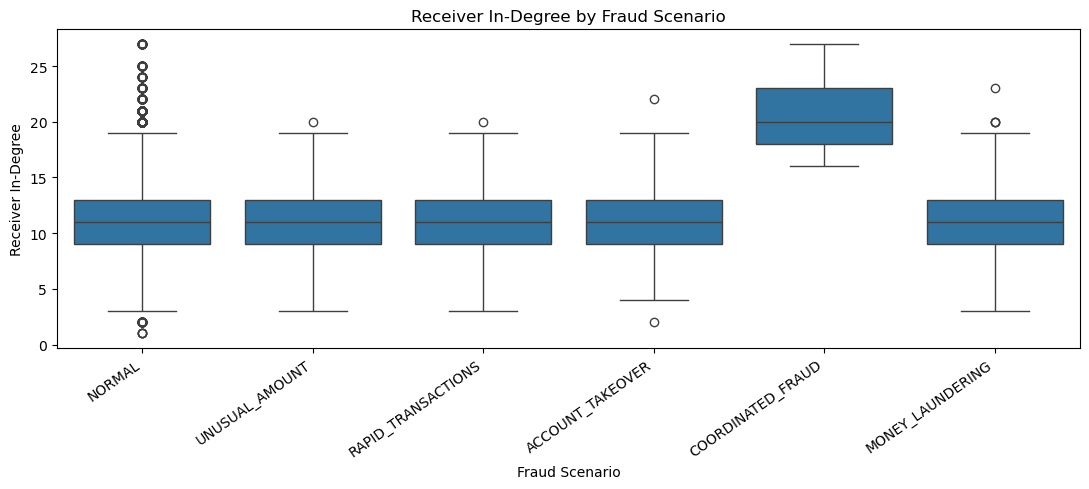

In [38]:

plt.figure(figsize=(11, 5))

sns.boxplot(
    data=transactions,
    x="fraud_scenario",
    y="receiver_in_degree"
)

plt.title("Receiver In-Degree by Fraud Scenario")
plt.xlabel("Fraud Scenario")
plt.ylabel("Receiver In-Degree")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [40]:

transactions["amount_log"] = np.log1p(transactions["amount"])

transactions["hour"] = transactions["timestamp"].dt.hour

transactions["day_of_week"] = (
    transactions["timestamp"].dt.dayofweek
)

transactions["is_weekend"] = (
    transactions["day_of_week"] >= 5
).astype(int)

transactions["transaction_type_code"] = (
    transactions["transaction_type"].astype("category").cat.codes
)

print("Transaction features created.")


Transaction features created.


In [41]:

transactions = transactions.sort_values(
    ["sender_id", "timestamp"]
).copy()

transactions["tx_count_1h"] = 0
transactions["tx_count_24h"] = 0
transactions["amount_sum_1h"] = 0.0
transactions["amount_sum_24h"] = 0.0

for sender_id, group in transactions.groupby("sender_id"):

    time_data = group.set_index("timestamp")

    transactions.loc[group.index, "tx_count_1h"] = (
        time_data["transaction_id"]
        .rolling("1h", closed="left")
        .count()
        .to_numpy()
    )

    transactions.loc[group.index, "tx_count_24h"] = (
        time_data["transaction_id"]
        .rolling("24h", closed="left")
        .count()
        .to_numpy()
    )

    transactions.loc[group.index, "amount_sum_1h"] = (
        time_data["amount"]
        .rolling("1h", closed="left")
        .sum()
        .to_numpy()
    )

    transactions.loc[group.index, "amount_sum_24h"] = (
        time_data["amount"]
        .rolling("24h", closed="left")
        .sum()
        .to_numpy()
    )

print("Time-window features created.")


Time-window features created.


In [42]:

transactions["previous_avg_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(lambda x: x.shift(1).expanding().mean())
)

transactions["previous_std_amount"] = (
    transactions.groupby("sender_id")["amount"]
    .transform(lambda x: x.shift(1).expanding().std())
)

transactions["has_transaction_history"] = (
    transactions["previous_avg_amount"].notna()
).astype(int)

transactions["amount_vs_avg"] = (
    transactions["amount"] /
    transactions["previous_avg_amount"].replace(0, np.nan)
)

transactions["amount_zscore"] = (
    (transactions["amount"] - transactions["previous_avg_amount"])
    / transactions["previous_std_amount"].replace(0, np.nan)
)

transactions[
    ["amount_vs_avg", "amount_zscore"]
] = transactions[
    ["amount_vs_avg", "amount_zscore"]
].replace([np.inf, -np.inf], np.nan).fillna(0)

print("Historical behavior features created.")


Historical behavior features created.


In [43]:

for group, columns in feature_groups.items():

    print(f"\n{group.upper()}")

    for column in columns:
        print(
            f"{column}:",
            column in transactions.columns
        )

print("\nFinal shape:", transactions.shape)



TRANSACTION_FEATURES
amount_log: True
hour: True
day_of_week: True
is_weekend: True
transaction_type_code: True

BEHAVIORAL_FEATURES
tx_count_1h: True
tx_count_24h: True
amount_sum_1h: True
amount_sum_24h: True
previous_avg_amount: True
previous_std_amount: True
amount_vs_avg: True
amount_zscore: True
has_transaction_history: True

GRAPH_FEATURES
sender_in_degree: True
sender_out_degree: True
sender_pagerank: True
receiver_in_degree: True
receiver_out_degree: True
receiver_pagerank: True

Final shape: (99975, 40)


In [45]:

# Önce kronolojik sıralama
transactions = transactions.sort_values(
    "timestamp"
).reset_index(drop=True)

# Gönderici hesabın daha önce yaptığı işlem sayısı
transactions["sender_prior_tx_count"] = (
    transactions.groupby("sender_id").cumcount()
)

# Alıcı hesabın daha önce aldığı işlem sayısı
transactions["receiver_prior_tx_count"] = (
    transactions.groupby("receiver_id").cumcount()
)

print(
    transactions[
        [
            "sender_id",
            "receiver_id",
            "timestamp",
            "sender_prior_tx_count",
            "receiver_prior_tx_count"
        ]
    ].head(10)
)


    sender_id receiver_id                     timestamp  \
0  ACC_005643  ACC_003307 2026-01-01 00:00:34.132897690   
1  ACC_002326  ACC_002724 2026-01-01 00:00:34.427735075   
2  ACC_002387  ACC_005028 2026-01-01 00:00:49.868826972   
3  ACC_002952  ACC_009419 2026-01-01 00:01:11.188848846   
4  ACC_004445  ACC_007201 2026-01-01 00:02:02.367877342   
5  ACC_001344  ACC_000202 2026-01-01 00:02:11.225255095   
6  ACC_001224  ACC_001265 2026-01-01 00:02:28.607309595   
7  ACC_008453  ACC_008485 2026-01-01 00:02:41.049623802   
8  ACC_002409  ACC_001846 2026-01-01 00:03:04.104537250   
9  ACC_000667  ACC_005339 2026-01-01 00:04:07.253897896   

   sender_prior_tx_count  receiver_prior_tx_count  
0                      0                        0  
1                      0                        0  
2                      0                        0  
3                      0                        0  
4                      0                        0  
5                      0              

In [46]:

feature_columns = [
    # Transaction Features
    "amount",
    "amount_log",
    "hour",
    "day_of_week",
    "is_weekend",
    "transaction_type_code",

    # Behavioral Features
    "tx_count_1h",
    "tx_count_24h",
    "amount_sum_1h",
    "amount_sum_24h",
    "previous_avg_amount",
    "previous_std_amount",
    "has_transaction_history",
    "amount_vs_avg",
    "amount_zscore",

    # Temporal Graph Features
    "sender_prior_tx_count",
    "receiver_prior_tx_count"
]

target_column = "is_fraud"

print("Number of features:", len(feature_columns))
print("\nMissing features:")

for col in feature_columns:
    if col not in transactions.columns:
        print(col)


Number of features: 17

Missing features:


In [47]:

model_data = transactions[
    feature_columns + [target_column]
].copy()

print("Model dataset shape:", model_data.shape)

print("\nTarget distribution:")
print(model_data[target_column].value_counts())

print("\nMissing values:")
print(model_data.isnull().sum())


Model dataset shape: (99975, 18)

Target distribution:
is_fraud
0    98476
1     1499
Name: count, dtype: int64

Missing values:
amount                         0
amount_log                     0
hour                           0
day_of_week                    0
is_weekend                     0
transaction_type_code          0
tx_count_1h                98145
tx_count_24h               71844
amount_sum_1h              98145
amount_sum_24h             71844
previous_avg_amount        10000
previous_std_amount        19996
has_transaction_history        0
amount_vs_avg                  0
amount_zscore                  0
sender_prior_tx_count          0
receiver_prior_tx_count        0
is_fraud                       0
dtype: int64


In [48]:

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_data.to_csv(
    OUTPUT_DIR / "model_dataset.csv",
    index=False
)

print("Model dataset saved successfully!")


Model dataset saved successfully!
